In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

: 

# EDA — Overview
This notebook performs exploratory data analysis for the credit risk dataset.

**Structure (matches Streamlit app):**
- Univariate — single-variable distributions and counts
- Bivariate — relationships between pairs of variables (scatter, grouped bars, boxplots)
- Correlation / Multivariate — heatmap and grouped analyses

Run the cells below in order. The sections are intentionally separated so you can copy them into the Streamlit app (or refer to the app tabs).

In [ ]:
df = pd.read_csv('credit_risk_dataset.csv')

# --- sanitize `person_age` so notebook matches the app (integers 1..100) ---
if 'person_age' in df.columns:
    df['person_age'] = pd.to_numeric(df['person_age'], errors='coerce')
    df['person_age'] = df['person_age'].clip(1, 100)
    if df['person_age'].isna().any():
        med = int(df['person_age'].median(skipna=True)) if not np.isnan(df['person_age'].median(skipna=True)) else 30
        df['person_age'].fillna(med, inplace=True)
    df['person_age'] = df['person_age'].astype(int)

# --- ensure `person_income` and `loan_amnt` are integers ---
for _col in ['person_income','loan_amnt']:
    if _col in df.columns:
        df[_col] = pd.to_numeric(df[_col], errors='coerce')
        medv = df[_col].median(skipna=True)
        if np.isnan(medv):
            medv = 0
        df[_col].fillna(int(medv), inplace=True)
        df[_col] = df[_col].round().astype(int)

# show head
df.head()

: 

In [ ]:
df.describe()

: 

In [ ]:
isnull = df.isnull().sum()
isnull

: 

In [ ]:
df.info

: 

In [ ]:
df['person_emp_length'].fillna(df['person_emp_length'].mean(), inplace=True)

: 

In [ ]:
df['loan_int_rate'].fillna(df['loan_int_rate'].mean(), inplace=True)    

: 

In [ ]:
df = df[df['person_age'] < 80]
df= df[df['person_emp_length'] < 50]

: 

In [ ]:
isnull = df.isnull().sum()
isnull

: 

## Univariate analysis

Single-variable plots to inspect distributions and class balance. Use these to detect skew, outliers and class imbalance before modeling.

In [ ]:
# Target class balance
plt.figure(figsize=(6,4))
ax = sns.countplot(x="loan_status", data=df, palette="Set1")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.title("Loan Status Class Balance (0 = Repaid, 1 = Default)")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.show()

: 

In [ ]:
# Plot loan intent distribution
plt.figure(figsize=(8,6))
sns.countplot(x="loan_intent", data=df, order=df["loan_intent"].value_counts().index, palette="viridis")

plt.title("Distribution of Loan Intent")
plt.xlabel("Loan Intent")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=45)
plt.show()


: 

In [ ]:
# Plot home ownership distribution
plt.figure(figsize=(8,6))
sns.countplot(x="person_home_ownership", data=df, 
              order=df["person_home_ownership"].value_counts().index, 
              palette="Set2")

plt.title("Distribution of Home Ownership")
plt.xlabel("Home Ownership Status")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=45)
plt.show()


: 

## Bivariate analysis

Plots showing relationships between two variables (e.g., income vs loan amount, debt-to-income vs loan amount, grouped barplots by category).

In [ ]:
# Create age groups (updated to cover 1–100)
df["age_group"] = pd.cut(
    df["person_age"],
    bins=[1,18,25,35,45,55,65,80,100],
    labels=["1-18","19-25","26-35","36-45","46-55","56-65","66-80","81-100"]
)

plt.figure(figsize=(10,6))
sns.boxplot(x="age_group", y="loan_amnt", data=df, palette="Set3")

plt.title("Loan Amount Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Loan Amount")
plt.show()

: 

In [ ]:
plt.figure(figsize=(12,7))
sns.barplot(x="loan_intent", y="loan_percent_income", 
            hue="loan_status", data=df, 
            estimator=lambda x: sum(x)/len(x), palette="Set2")

plt.title("Average Debt-to-Income Ratio by Loan Intent and Loan Status")
plt.xlabel("Loan Intent")
plt.ylabel("Average Loan Percent Income")
plt.xticks(rotation=45)
plt.legend(title="Loan Status")
plt.show()


: 

## Correlation / Multivariate analysis

Heatmap and grouped analyses to inspect multivariate relationships and feature correlations (useful for feature selection and multicollinearity checks).

In [ ]:
# Encode categorical features from the CLEANED dataframe (not the raw CSV,
# so the heatmap reflects the same data used everywhere else in this notebook)
df_encoded = df.copy()
for col in ["loan_grade", "person_home_ownership", "loan_intent"]:
    df_encoded[col] = df_encoded[col].astype("category").cat.codes
if df_encoded["cb_person_default_on_file"].dtype == object:
    df_encoded["cb_person_default_on_file"] = df_encoded["cb_person_default_on_file"].map({"Y": 1, "N": 0})
df_encoded = df_encoded.rename(columns={"cb_person_cred_hist_length": "credit_hist_length"})

: 

In [ ]:
# Correlation heatmap of encoded features
num_df = df_encoded.select_dtypes(include=[np.number])
plt.figure(figsize=(12,9))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Encoded Features")
plt.tight_layout()
plt.show()

: 

In [ ]:
# Encode categorical features
df["cb_person_default_on_file"] = df["cb_person_default_on_file"].map({"Y":1,"N":0})

plt.figure(figsize=(12,7))
sns.barplot(x="loan_grade", y="loan_int_rate", 
            hue="cb_person_default_on_file", data=df, 
            estimator=lambda x: sum(x)/len(x), palette="Set2")

plt.title("Average Loan Interest Rate by Loan Grade and Default History")
plt.xlabel("Loan Grade")
plt.ylabel("Average Interest Rate")
plt.legend(title="Past Default on File")
plt.show()


: 

In [ ]:
df.to_csv("clean_data.csv", index = False)

: 

## Model evaluation — AUC-ROC

Trains the **same RandomForest pipeline used in the Streamlit app (`app1.py`)** on a stratified train/test split, then plots the ROC curve with its AUC score. This shows how well the model separates defaulters from non-defaulters across all classification thresholds.

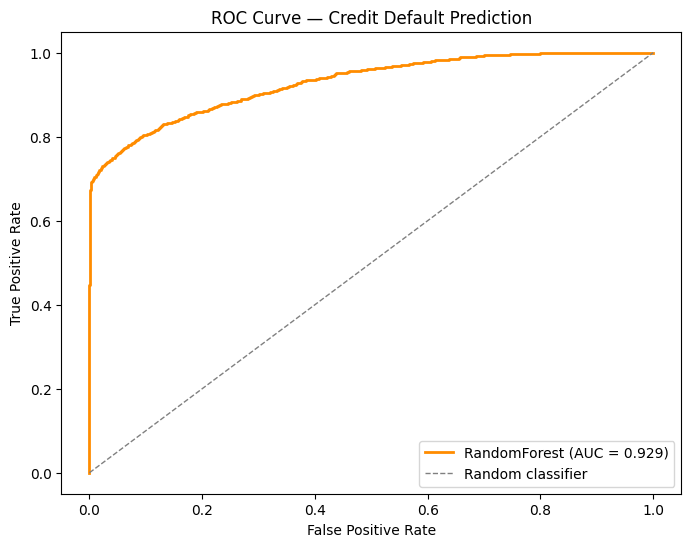

AUC-ROC: 0.9287


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score

X = df.drop(columns=["loan_status", "age_group"], errors="ignore")
y = df["loan_status"]

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="mean")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, max_depth=15,
                                     class_weight="balanced", random_state=42)),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=42)
pipeline.fit(X_train, y_train)

y_proba = pipeline.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_proba)
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"RandomForest (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], color="grey", lw=1, linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Credit Default Prediction")
plt.legend(loc="lower right")
plt.show()

print(f"AUC-ROC: {auc:.4f}")